## Machine Learning Fundamentals

Machine learning (ML) is a branch of artificial intelligence that uses algorithms to find patterns in data and make predictions or decisions on new data without explicit, hard-coded rules. 

Fundamentally, we are usually trying to optimize a constraint or cost. This cost $c$ defines the **penalty for an incorrect classification / prediction** our model makes versus the true value.

---


### Supervised Learning 

Supervised learning learns from being given **labelled data** (x and y pairs). The goal is to be able to map specific inputs of x to output y. 

Two kinds of task:
* **Regression:** Predicting a number. (Housing price, stock return etc.)
* **Classification:** Predicting a category. (Survive or died, spam or ham etc.)

### Unsupervised Learning

Unsupervised learning learns from being given **unlabelled data** (x values only). The goal is to find **underlying patterns or structures** in the data. 

Task depends on what we are trying to find in our data:
* **Clustering:** Group similar data points together. (Grouping customers by segments etc.)
* **Dimensionality Reduction:** Compress many variables (Big dataset) into a few that keep most of the information (Smaller dataset).
* **Anomoly Detection:** Find unusual points that don't fit the usual pattern. (Fraud detection etc.)
* **Association Rules:** Find items that tend to occur together.
* **Density Estimation:** Estimate the underlying distribution of the data.


## Linear Regression

One of the most "basic" machine learning models is univariate (single variable) linear regression. The function attempts to predict a value denoted by $\hat{y}$ where its specific inputs are $\vec{x} \in X$.

Linear regression gives us **two controls** at our disposal: 
* weight vector $\vec{w}$ that contains the weights for each input $x$
* a scalar bias $b$

### Model

The **linear regression function (model)** for the final predicted value $\hat{y}$ is given by:

$$\hat{y} = f_{\vec{w},b}(\vec{x}) = \vec{w} \cdot \vec{x} + b$$

### Cost function

There are many cost functions for regression, but commonly we use the **Mean Squared Error (MSE)**: 

$$J(w, b) = \frac{1}{2m}\sum_{i=1}^{m} \left( \hat{y}_i - y_i \right)^2$$

Where $n$ is the size of our test set. 

We want to find the values $(w, b)$ such that: 

$$\min_{w,\, b} \; J(w, b)$$



## Gradient Descent

Gradient descent is an algorithm for finding the **minimum of a function** by repeatedly taking small steps downhill. In machine learning, the function is usually the cost $J$, and the minimum is where the model's parameters fit the data best. 

### General Algorithm

Gradient descent algorithm is given by: 

$$\theta_{\text{new}} \leftarrow \theta_{\text{old}} - \alpha \, \nabla J(\theta)$$

* $\theta$: Parameter being learned
* $\alpha$: The learning rate (step size)
* $\nabla J(\theta)$: Slope at the current point

In context of linear regression, we want to **simultaneously update** $w$ and $b$: 

$$
\begin{aligned}
w_{\text{new}} &\leftarrow w_{\text{old}} - \alpha \frac{\partial}{\partial w} J(w, b) \\
b_{\text{new}} &\leftarrow b_{\text{old}} - \alpha \frac{\partial}{\partial b} J(w, b)
\end{aligned}
$$

and repeat the above steps until **convergence**.

Note: *Simultaneously* here means that we calculate the partial derivatives for all the parameters before updating any of the parameters. 

This method of computing gradient descent is known as **"Batch"** gradient descent. 
* Each step of gradient descent requires us to calculate the derivative for the sum of **all the training examples.**
* Other methods of gradient descent calculates only **subsets** of all the training data. 

### Learning Rate

When learning rate is **too small**:
* Gradient descent still heads towards the minimum, but will do require many iterations. 

When learning rate is **too large**:
* Steps overshoot the minimum, each steps causes the point to zig and zag across the minimum. 
* If severe, each steps lands higher than the last. The cost grows instead of shrinking and diverge. 

Near a **local minimum**,
* Deverivative (the slope) becomes smaller
* So the update step $\alpha \cdot \nabla J(\theta)$ become smaller

Hence we can reach a minimum without decreasing the learning rate.

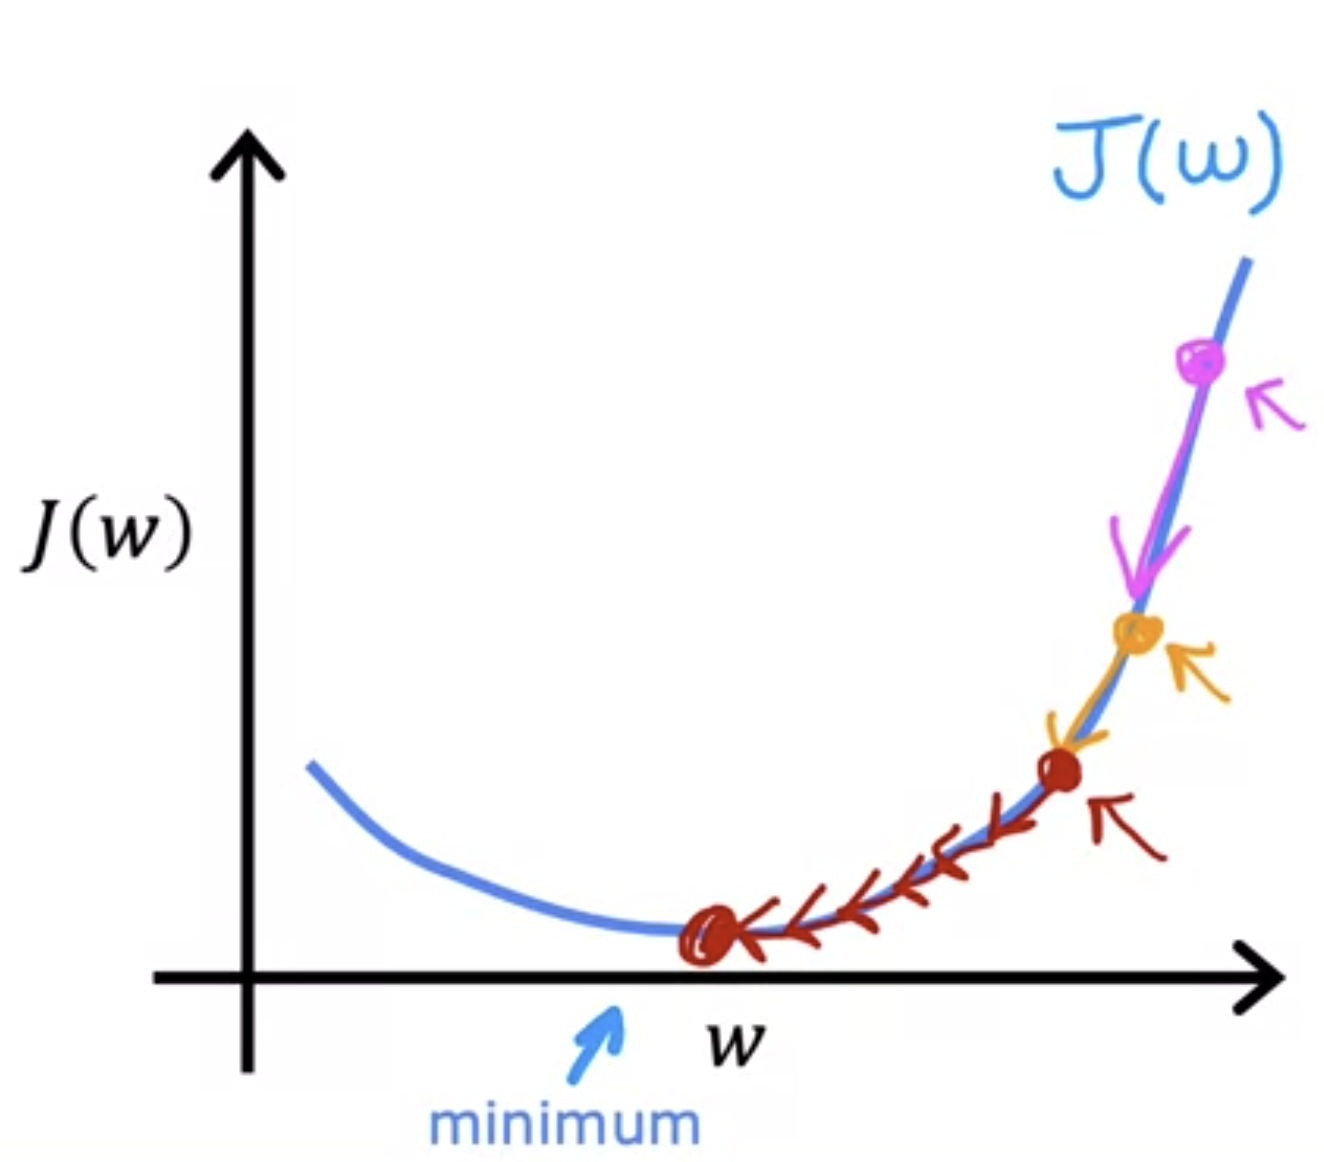

### Gradient Descent for Linear Regression

The problem with gradient descent is that we may not always find the **global minimum**. Depending on starting position, we can obtain a **local minimum**. 

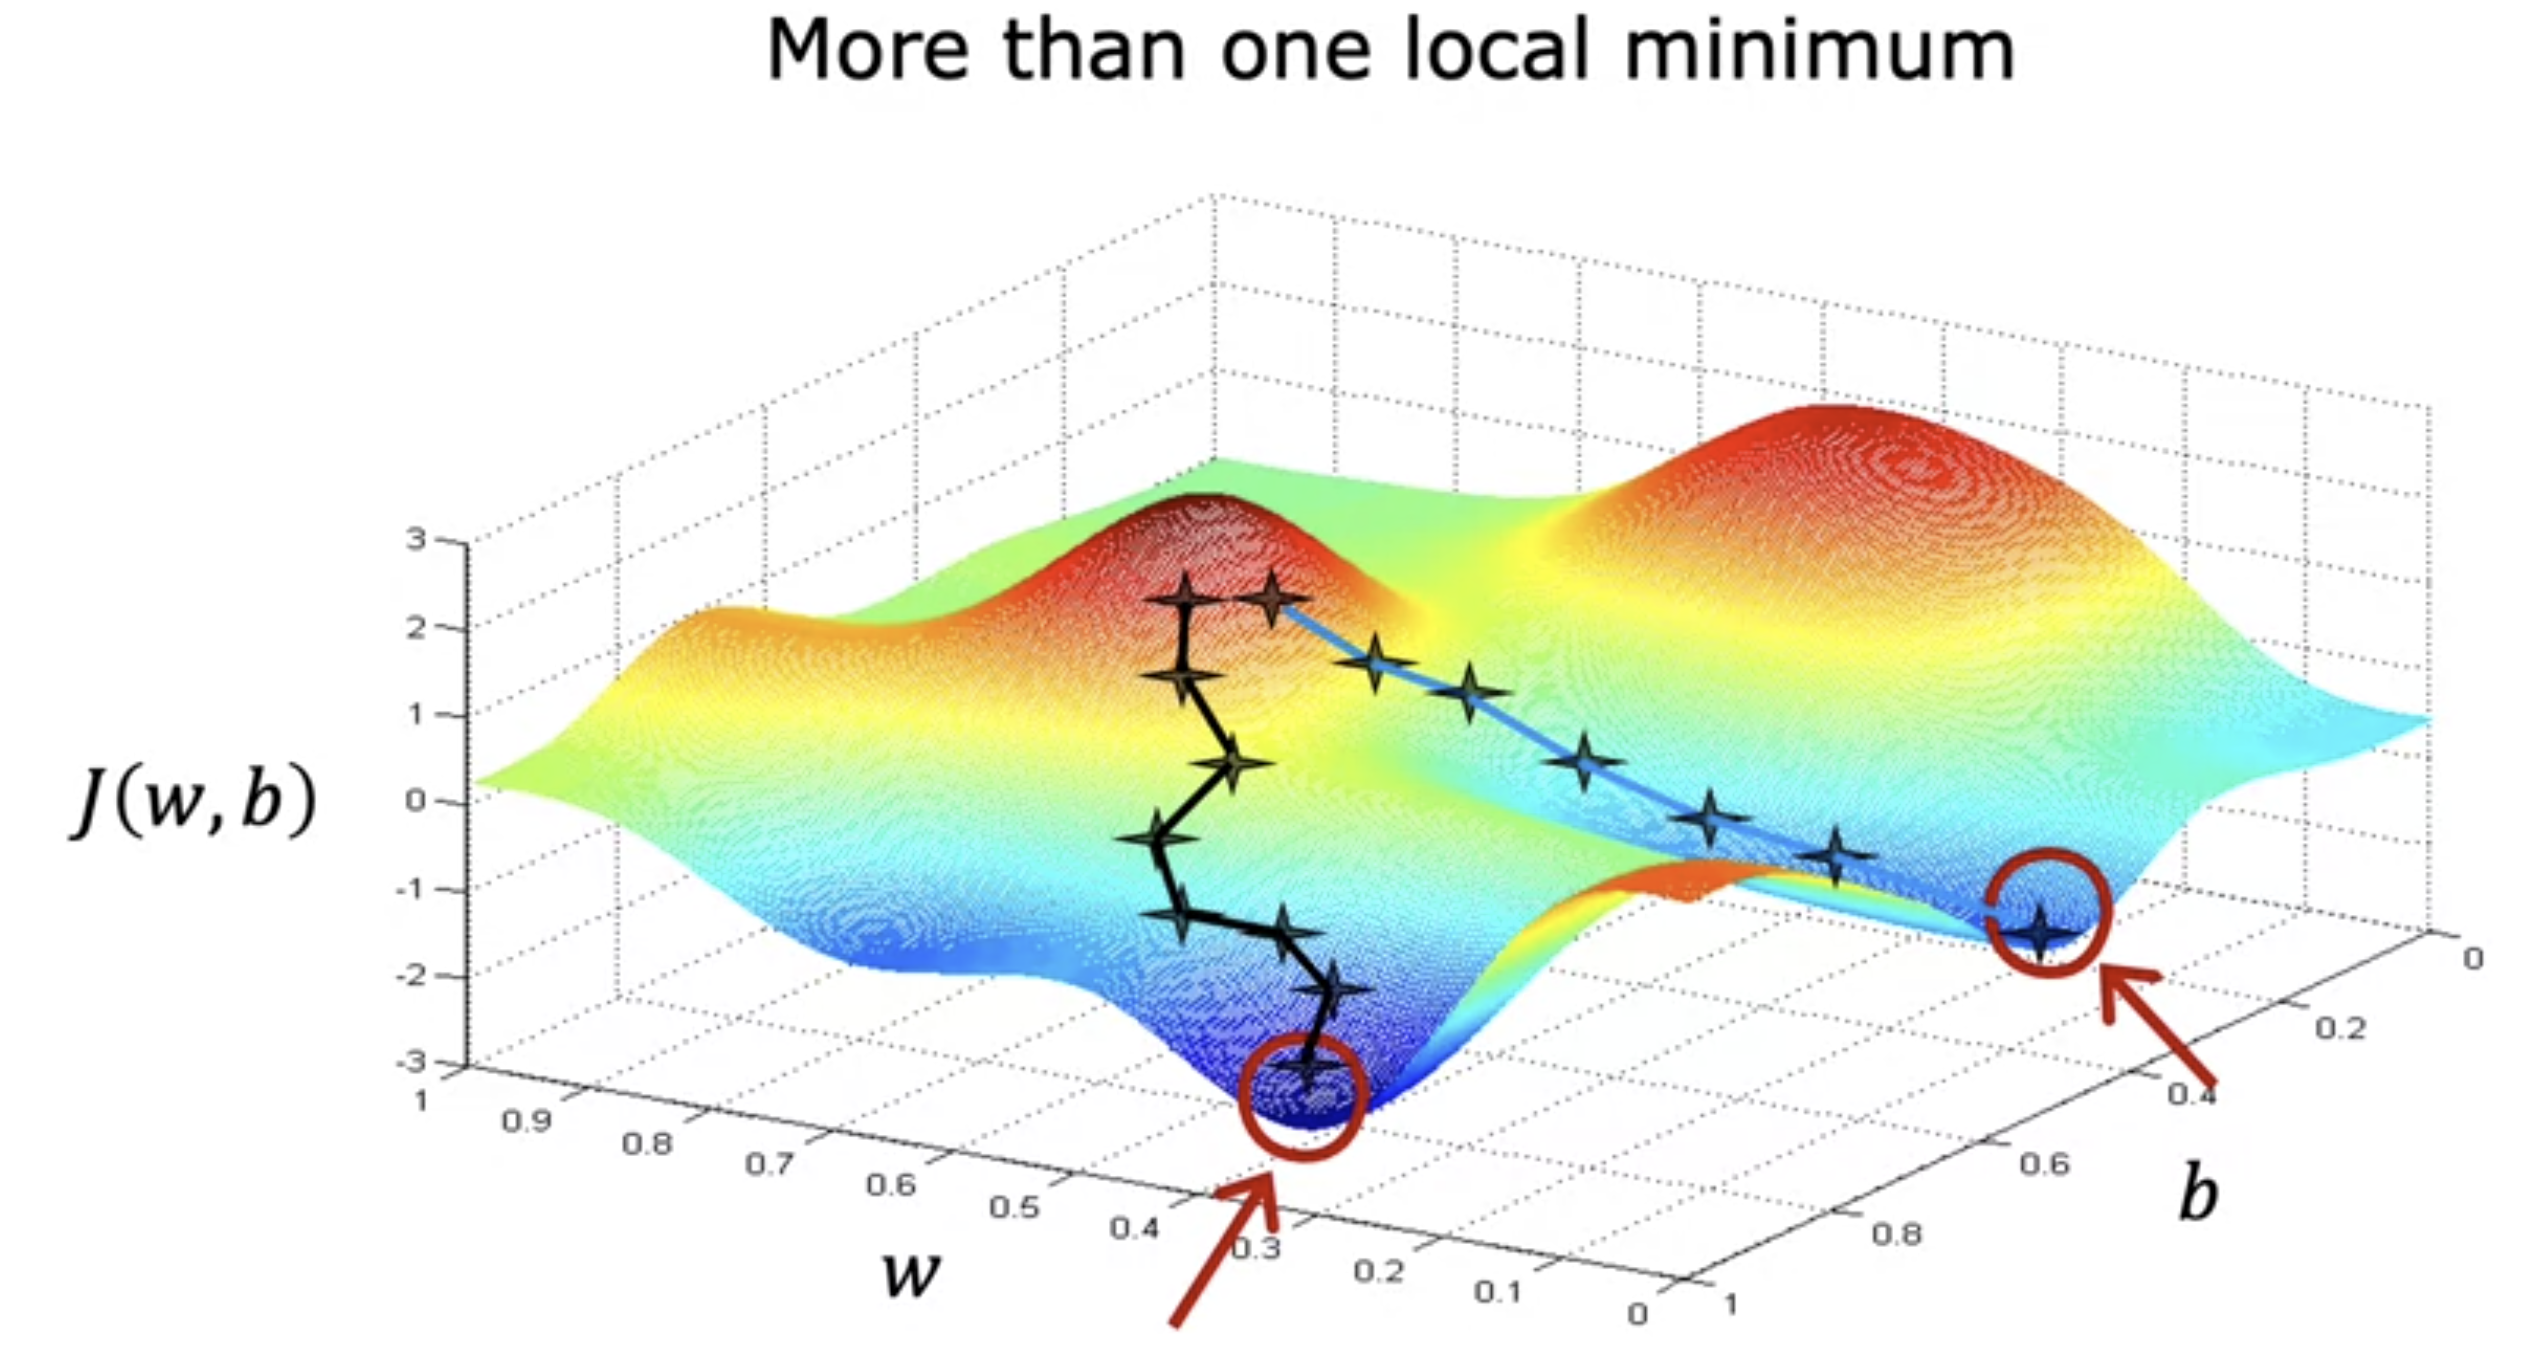

The **Mean Least Squares Cost Function** within regression, will never have multiple local minima. It has a **single global minima** as the function is a **convex function (bowl-shape)**.

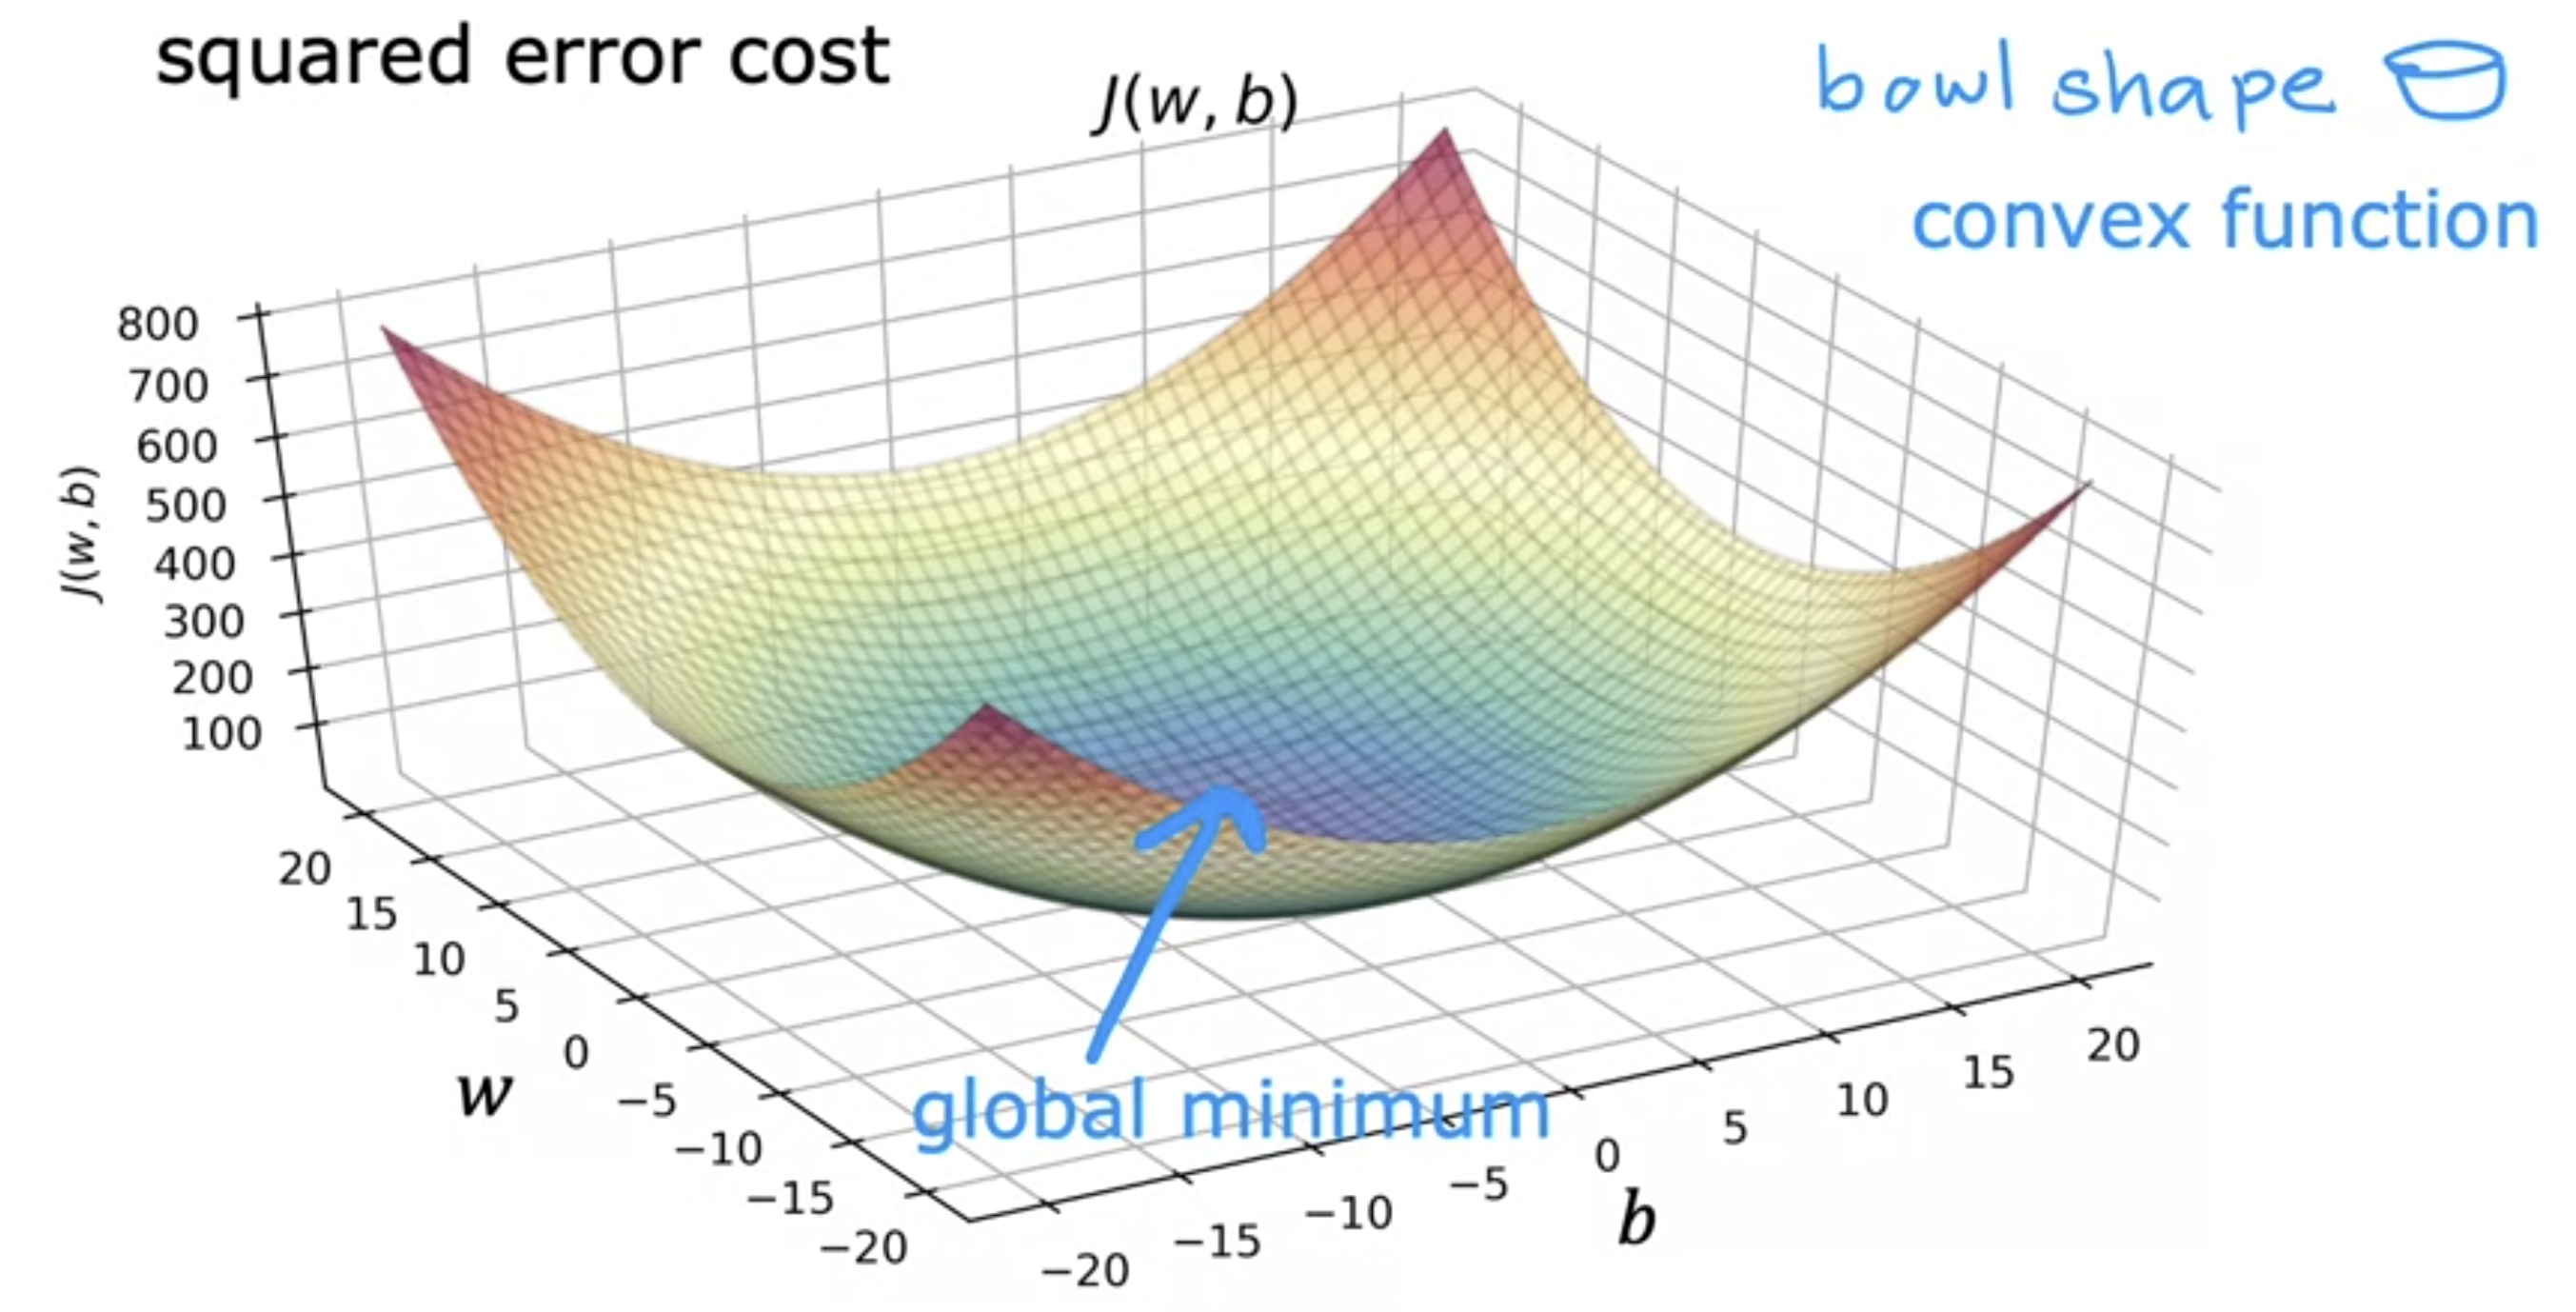

---

## Multiple Linear Regression

Multiple linear regression predicts $\hat{y}$ from **several features** at once, giving each its own weight. 

### Model

$$
\begin{aligned}
f_{\vec{w},b}(\vec{x}) &= w_1x_1 + w_2x_2 + \dots + w_nx_n + b \\
&= \vec{w} \cdot \vec{x} + b
\end{aligned}
$$

Where: 
* $\vec{x}$ is the **input vector** of features represented by $(x_1, \dots , x_n)$
* $n$ is the number of features

With parameters:
* $\vec{w}$ the corresponding weights represented by $(w_1, \dots , w_n)$ 
* $b$ is a scalar bias

Note: **multiple linear** regression differs from **multivariate** regression

### Cost Function

$$
J(\vec{w}, b) = \frac{1}{2m} \sum_{i=1}^{m} \left( f_{\vec{w},b}(\vec{x}^{(i)}) - y^{(i)} \right)^2
$$

Where $m$ is the number of training examples and $\vec{x}^{(i)}$ is the $i$-th training example.

### Gradient Descent for Multiple Linear Regression

We run gradient descent by **simultaneously updating** $\vec{w}$ and $b$:

$$
\begin{aligned}
w_j &\leftarrow w_j - \alpha \frac{\partial}{\partial w_j} J(\vec{w}, b) \quad \text{for } j = 1, \dots, n \\
b &\leftarrow b - \alpha \frac{\partial}{\partial b} J(\vec{w}, b)
\end{aligned}
$$

where the partial derivatives are:

$$
\begin{aligned}
\frac{\partial}{\partial w_j} J(\vec{w}, b) &= \frac{1}{m} \sum_{i=1}^{m} \left( f_{\vec{w},b}(\vec{x}^{(i)}) - y^{(i)} \right) x_j^{(i)} \\
\frac{\partial}{\partial b} J(\vec{w}, b) &= \frac{1}{m} \sum_{i=1}^{m} \left( f_{\vec{w},b}(\vec{x}^{(i)}) - y^{(i)} \right)
\end{aligned}
$$

and repeat the above steps until **convergence**.



## Feature Scaling

When features are on very different scales (2000 to 5 etc.):
* A single learning rate will cause too big of a step on the bigger variable and too small a step on the smaller variable. 
* Cost function's contours will become long and narrow.

Benefits of Scaling: 
* Makes contour more circular, gradient descent converges faster.
* Allows us to reach minimum faster. 

### Methods 

**1. Divide by max**
$$x_j^{\text{scaled}} = \frac{x_j}{\max(x_j)}$$
- Range roughly $[0, 1]$ for positive values.

**2. Mean normalisation**
$$x_j^{\text{scaled}} = \frac{x_j - \mu_j}{\max(x_j) - \min(x_j)}$$
- Range roughly $[-1, 1]$, centred at 0.

**3. Z-score normalisation**
$$x_j^{\text{scaled}} = \frac{x_j - \mu_j}{\sigma_j}$$
- Mean 0, standard deviation 1.
- Each value = number of standard deviations from the mean.

## QC on Gradient Descent

Objective: 

$$\min_{\vec{w},\, b} \; J(\vec{w}, b)$$

The best method to ensure gradient descent is working correctly is to plot the **learning curve**. That is the cost function J against the number of iterations.

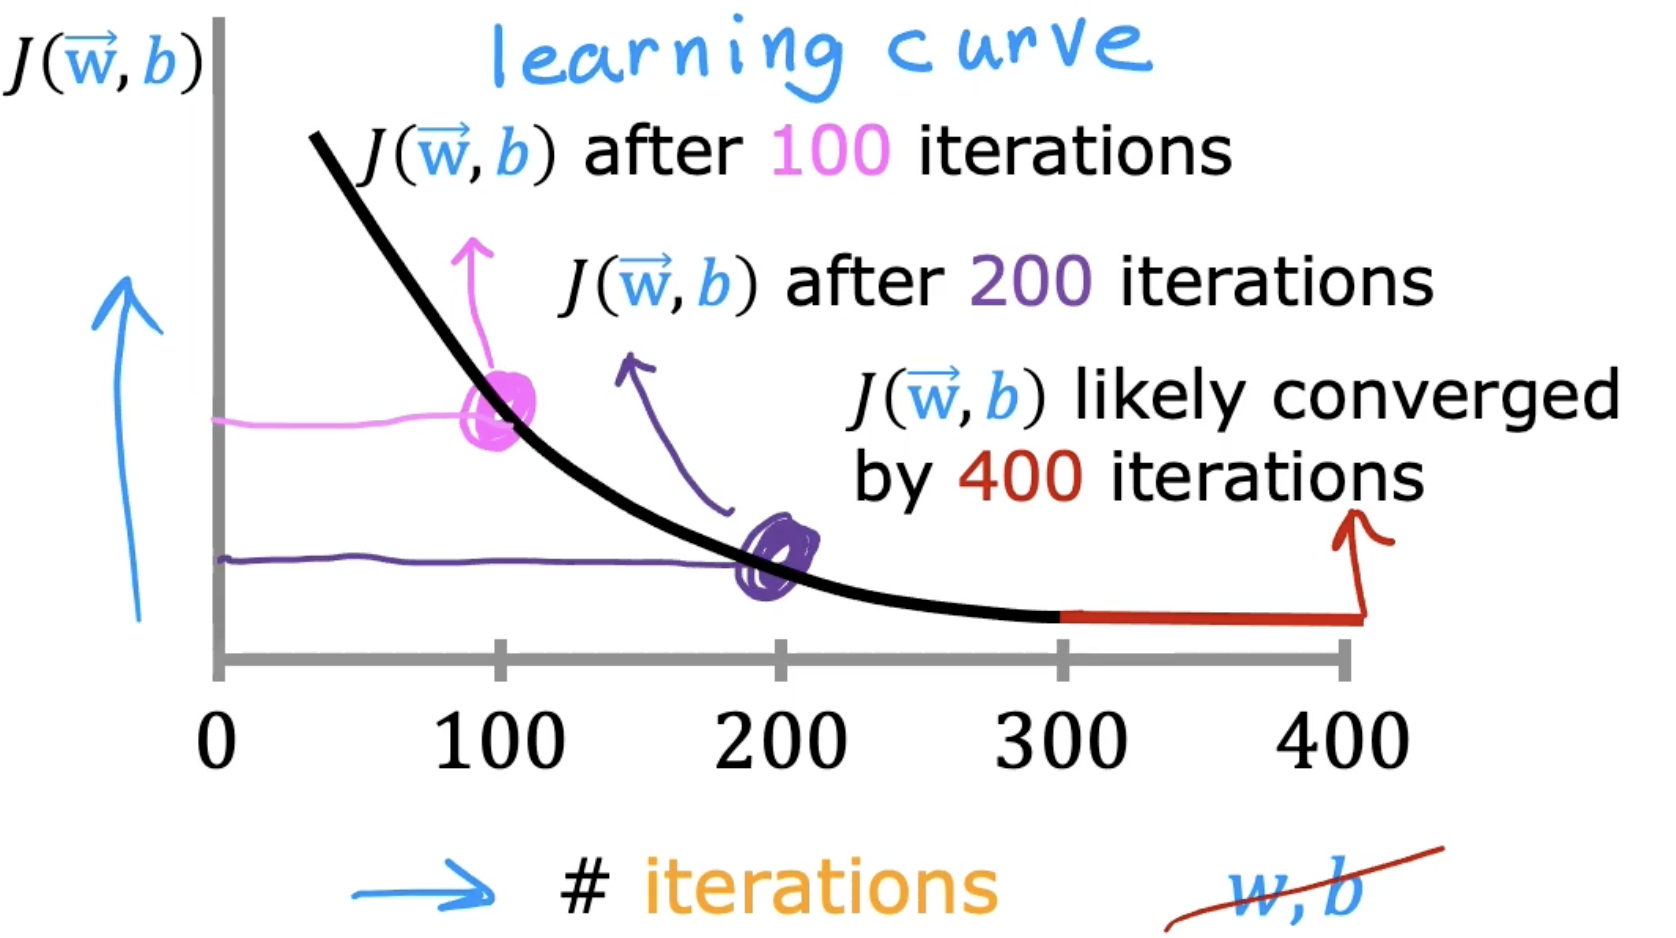

When gradient descent is implemented correctly we should see a **constantly decreasing function**.

If there is an **increase**, this implies that either:
1. Learning rate (alpha) was chosen poorly (too large)
2. Programming bug

### Automatic Convergence Test

To conduct the **automatic convergence test**, we choose a small number $\epsilon$ and **declare convergence** when:

$$J(w, b) \text{ decreases} \le \epsilon \text{ in one iteration.}$$

This is the less popular method by convention compared to plotting the learning curve due to ambiguity of choice of $\epsilon$.

### Choosing an Appropriate Learning Rate

A method we can use to find an effective learing rate is to **plot the learning curve for a few values of alpha**. 

We want to identify which values for alpha are **too small** and which are **too big**. We then select the largest possible value from this range. 

## Feature Engineering

Creating or transforming input features using knowledge of the problem, so a model can learn patterns more easily.

**Why it matters for linear regression**
- Linear regression can only fit a weighted sum of its features: $\hat{y} = w_1 x_1 + \cdots + w_n x_n + b$.
- If a feature has a curved relationship with $y$, transform it so the relationship becomes roughly linear.
- Each column can get its own transformation, e.g. $\hat{y} = w_1 x_1 + w_2 \sqrt{x_2} + w_3 \log(x_3) + b$.

**Choosing transformations**
- Plot $y$ against each feature to see its shape.
- Bends upward: try $x^2$. Levels off: try $\sqrt{x}$ or $\log x$.
- Check residuals after fitting; curved patterns mean a feature needs a different transformation.

**Transformation vs scaling**
- Transformation changes the shape of a relationship (per column).
- Scaling (z-score, min-max) changes only the range, to help gradient descent.
- **Transform first, then scale.**

## Polynomial Regression

**Polynomial regression is feature engineering.** We take each raw feature, transform it using its powers, and hand everything to ordinary linear regression. 

Think of it as ordinary regression where features are transformed by its power to form a **linear relationship with the target variable**.

$$\hat{y} = w_1 x + w_2 x^2 + w_3 x^3 + b$$

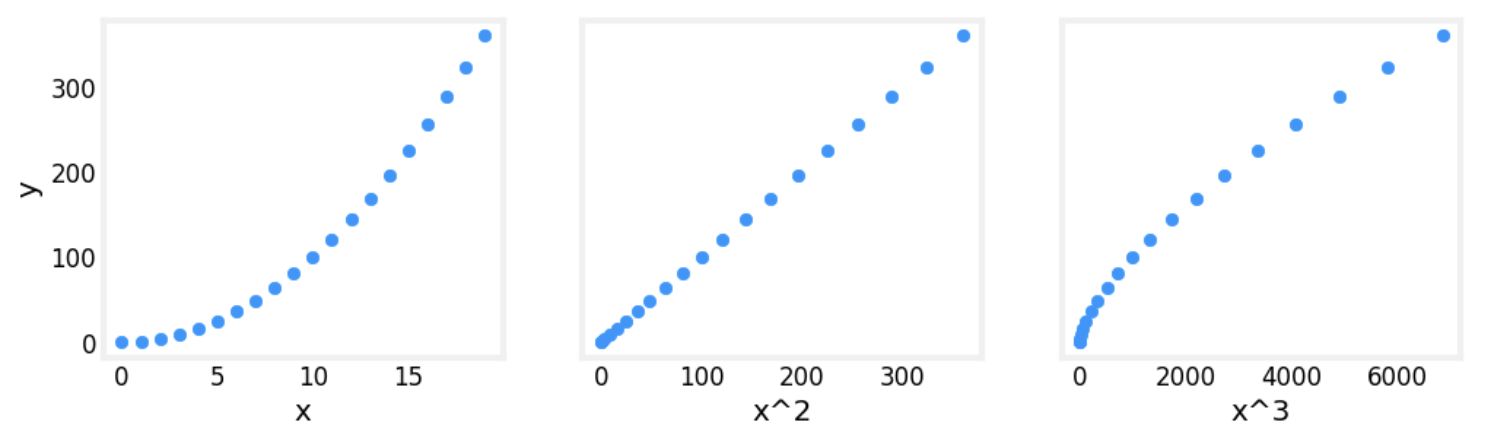

$x^2$ *demonstrates the transformation of a curved x feature to a linear one which is a better fit for linear regression.*

**Using it**
- Always scale polynomial features, since feature in higher powers can be very large.
- Choose the degree using validation data:
  - Too low: underfits (misses the curve).
  - Too high: overfits (fits noise, poor on new data).

---

## Classification

With classification, we are typically trying to **predict categorical outcomes.**

More specifically, $\hat{y}$ is either 1 (positive outcome) or 0 (negative outcome). This is known as **binary classfication** where we only have 2 outcomes. 

### Sigmoid Function

The sigmoid function is the **key function** that allows logistic regression to output binary outcomes.

$$g(z) = \frac{1}{1+e^{-z}}$$

The sigmoid function takes any real number and squashes it into the range $(0, 1)$, in an S-shaped curve. 

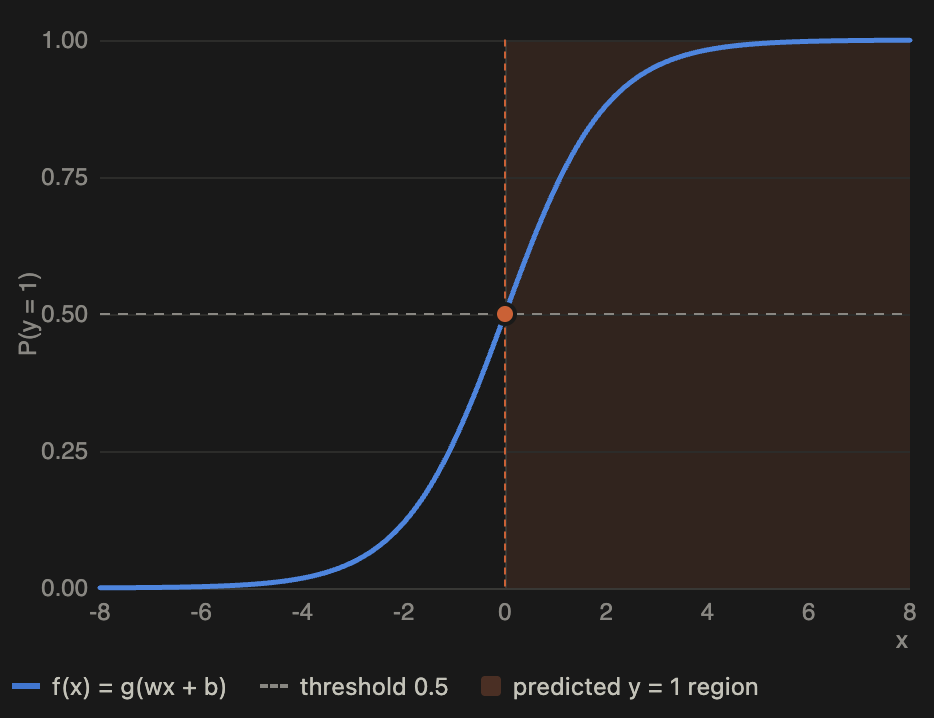

**Properties of the sigmoid function:**
* Large negative values are closer to 0
* Large positive values are closer to 1
* When z = 0, g(z) = 0.5 exactly

## Logistic Regression

Logistic regression is a model for **classification** which predicts which of two categories a variable belongs to. 

### Model

We compute the usual linear regression $z$, then pass it into the sigmoid function.

$$
z = \vec{w} \cdot \vec{x} + b \\
f_{\vec{w}, b}(\vec{x}) = g(z) = \frac{1}{1+e^{-(\vec{w} \cdot \vec{x} + b)}}
$$

We read the output as a probability of a **positive outcome**:

$$f_{\vec{w}, b}(\vec{x}) = P(y = 1| \vec{x})$$

where, 

$$0 <f_{\vec{w}, b}(\vec{x}) < 1$$

### Prediction and Decision Boundary

By default we classify / predict:
* $\hat{y} = 1$ when $z \ge 0.5$ (variables on the **right**)
* $\hat{y} = 0$ when $z < 0.5$ (variables on the **left**)

We call the line that **seperates positive and negative predictions** as the decision boundary. 

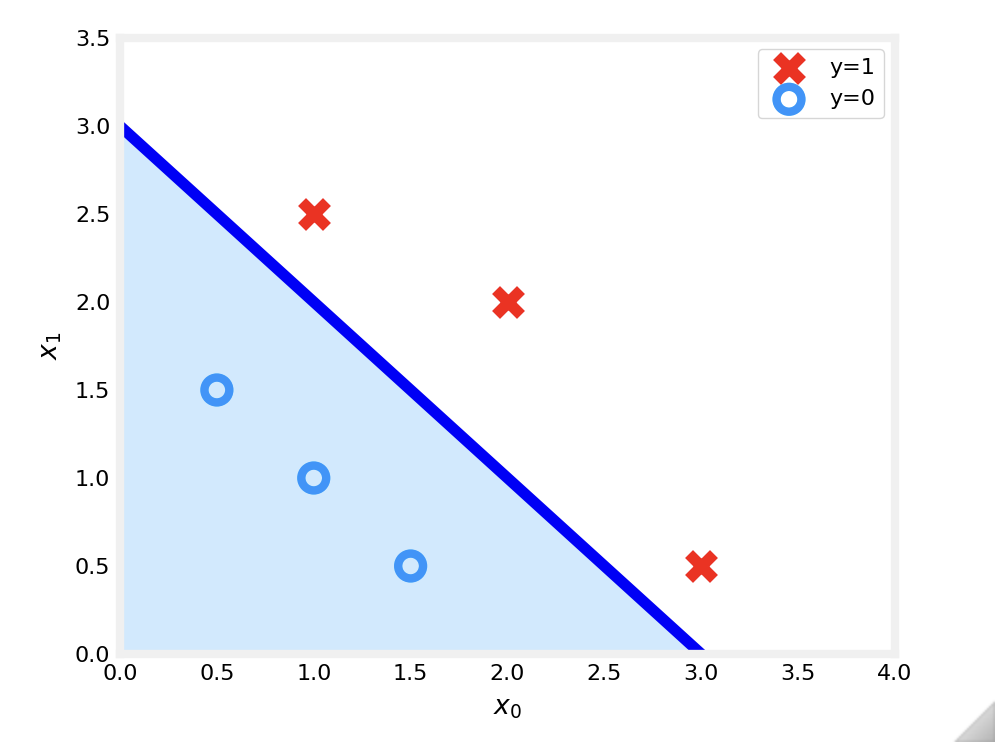

More specifically, the decision boundary (line in 2D, hyperplane in higher dimensions) that seperates the features occurs when $z = 0$.

$$\text{Decision boundary}: z = \vec{w} \cdot \vec{x} + b = 0$$



### Non-linear Decision Boundaries

By applying polynomial regression on the linear function before passing it through the sigmoid function. We are able to obtain non-linear and more complex decision boundaries. 

This implies logistic regression can be an **extremely versatile tool**, capable of fitting complex data. 


## Cost function for Logistic Regression

**Motivation:** Given a traning set, how do we choose $\vec{w} = [w_1, w_2, \dots , w_n] \text{ and } b?$

**Definition note:**
* The **Loss** $L$ is a measure of the difference of a single example to its target value.
* The **Cost** $J$ is a measure of the average losses over the training set.

---

For **linear regression:**

**Loss function**

$$L\left(f_{\vec{w}, b}(\vec{x}^{(i)}), y^{(i)}\right) = \frac{1}{2}\left(f_{\vec{w}, b}(\vec{x}^{(i)})- y^{(i)}\right)^2$$

**Cost function** 

$$
\begin{align*}
J(\vec{w}, b) &= \frac{1}{m} \sum_{i=1}^{m} L\left(f_{\vec{w}, b}(\vec{x}^{(i)}), y^{(i)}\right) \\
&= \frac{1}{m} \sum_{i=1}^{m} \frac{1}{2}\left(f_{\vec{w}, b}(\vec{x}^{(i)})- y^{(i)}\right)^2 \\ 
&= \frac{1}{2m} \sum_{i=1}^{m} \left(f_{\vec{w}, b}(\vec{x}^{(i)})- y^{(i)}\right)^2
\end{align*}
$$

Where $f_{\vec{w}, b}(\vec{x}) = \vec{w} \cdot \vec{x}+ b$

---

For **logistic regression:**

The **loss function: log loss**

$$
L\left(f_{\vec{w}, b}(\vec{x}^{(i)}), y^{(i)}\right) =
\begin{cases}
-\log\left(f_{\vec{w}, b}(\vec{x}^{(i)})\right) & \text{if } y^{(i)} = 1 \\
-\log\left(1 - f_{\vec{w}, b}(\vec{x}^{(i)})\right) & \text{if } y^{(i)} = 0
\end{cases} \\
$$

Simplifying the loss function, we arrive at 

$$L\left(f_{\vec{w}, b}(\vec{x}^{(i)}), y^{(i)}\right) = 
-y^{(i)}\log\left(f_{\vec{w},b}\left(\vec{x}^{(i)}\right)\right) - \left(1 - y^{(i)}\right)\log\left(1 - f_{\vec{w},b}\left(\vec{x}^{(i)}\right)\right)$$

The equation above simply **splits into the piecewise function** when $y^{(i)} = 0 \text{ or } 1$

**Cost function**

$$
\begin{align*}
J(\vec{w}, b) &= 
\frac{1}{m} \sum_{i=1}^{m} \left[L\left(f_{\vec{w}, b}(\vec{x}^{(i)}), y^{(i)}\right)\right] \\ &= 
-\frac{1}{m} \sum_{i=1}^{m} \left[y^{(i)}\log\left(f_{\vec{w},b}\left(\vec{x}^{(i)}\right)\right) + \left(1 - y^{(i)}\right)\log\left(1 - f_{\vec{w},b}\left(\vec{x}^{(i)}\right)\right)\right]
\end{align*}
$$

Where $f_{\vec{w}, b}(\vec{x}) = \frac{1}{1+e^{-(\vec{w} \cdot \vec{x} + b)}}$

The **cost function for logistic regression** above is **convex**, which allows gradient descent to reach a global minimum. 

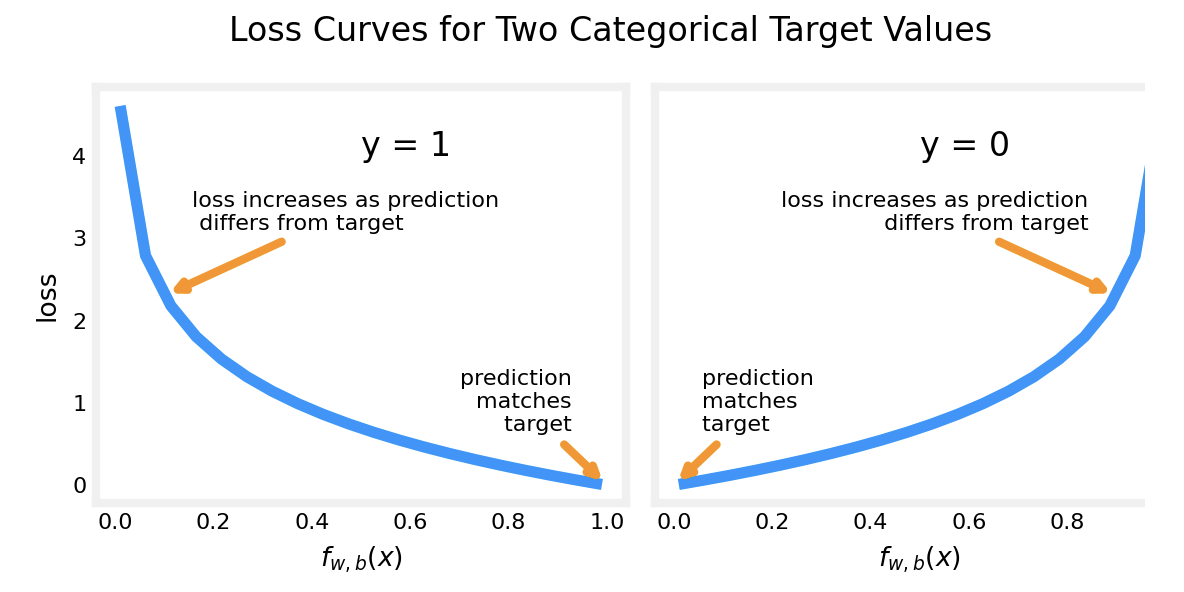

## Gradient Descent for Logistic Regression

Given the **cost function**

$$J(\vec{w}, b) = -\frac{1}{m} \sum_{i=1}^{m} \left[y^{(i)}\log\left(f_{\vec{w},b}\left(\vec{x}^{(i)}\right)\right) + \left(1 - y^{(i)}\right)\log\left(1 - f_{\vec{w},b}\left(\vec{x}^{(i)}\right)\right)\right]$$

we repeat the following updates **simultaneously until convergence** 

$$
\begin{align*}
w_j &\leftarrow w_j - \alpha \frac{\partial}{\partial w_j} J(\vec{w}, b) \\
b &\leftarrow b - \alpha \frac{\partial}{\partial b} J(\vec{w}, b)
\end{align*}
$$

where the partial derivatives are similarly:

$$
\begin{aligned}
\frac{\partial}{\partial w_j} J(\vec{w}, b) &= \frac{1}{m} \sum_{i=1}^{m} \left( f_{\vec{w},b}(\vec{x}^{(i)}) - y^{(i)} \right) x_j^{(i)} \\
\frac{\partial}{\partial b} J(\vec{w}, b) &= \frac{1}{m} \sum_{i=1}^{m} \left( f_{\vec{w},b}(\vec{x}^{(i)}) - y^{(i)} \right)
\end{aligned}
$$

we note that although the partial derivatives are the same, **$f_{\vec{w}, b}(\vec{x})$ differs.**

$$
\text{linear regression: } f_{\vec{w}, b}(\vec{x}) = \vec{w} \cdot \vec{x} + b \\
\text{logistic regression: } f_{\vec{w}, b}(\vec{x}) = \frac{1}{1+e^{-(\vec{w} \cdot \vec{x} + b)}}
$$


## Problems when fitting data

### Bias and Variance

Assuming the data comes from $y = f(x) + \epsilon$, where $\epsilon$ is the noise with variance $\sigma^2$. 

When we fit a model $\hat{f}$ on random training samples, its **expected squared error** at a point $x$ splits into 3 parts: 
* **Bias** how far the average prediction sits from the true value. 
* **Variance** is how much the prediction changes when you train a different sample.
* **Noise (irreducible)** $\sigma^2$ can't be reduced by any model.

### Overfitting and Underfitting

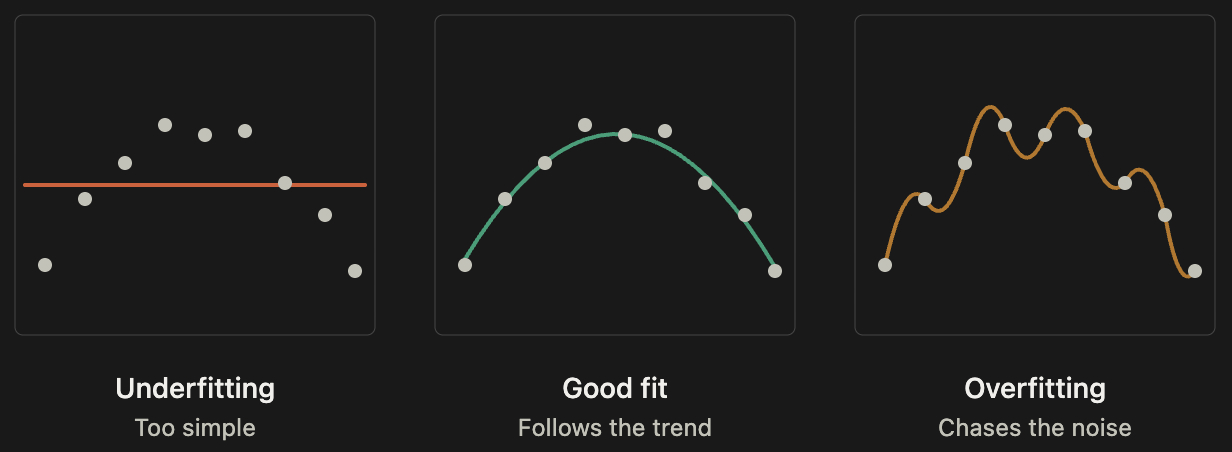

**Underfitting** is when the model is ***too simple** to learn the real pattern of the data (ie. the model hasn't learned enough).
* An underfit model has **high bias:** the flat line is wrong no matter whatever sample you train it on.

**Overfitting** is when the model **learns the training data too closely.** This data will score well on training data but poorly on new data. 
* An overfit model has **high variance:** a new samples produces a completely different wiggly curve.

Note: These fitting issues can show up in both regression and classification!

### Addressing these issues

**Adressing overfitting:**
1. Collect more data
2. Select features (reduce features)
3. Reduce size of weights (Regularization, recommended!)

## Regulatization

**Regularization** is a technique that stops a model from overfitting by assigning smaller values to $(w_1, w_2, \dots, w_n, b)$.
* A simpler model is less likely to overfit

### Cost function regulatization

$$
\min_{\vec{w},b} J(\vec{w},b)
= \min_{\vec{w},b}
\left[
\frac{1}{2m} \sum_{i=1}^{m} \left( f_{\vec{w},b}\!\left(\vec{x}^{(i)}\right) - y^{(i)} \right)^2
+ \frac{\lambda}{2m} \sum_{j=1}^{n} w_j^2
\right]
$$

Where
$$
\text{mean squared error (fit data): } \frac{1}{2m} \sum_{i=1}^{m} \left( f_{\vec{w},b}\!\left(\vec{x}^{(i)}\right) - y^{(i)} \right)^2 \\
\text{regularization term (keeps $w_j$ small): } \frac{\lambda}{2m} \sum_{j=1}^{n} w_j^2 \\ 
\text{regularization paramater: } \lambda \text{ such that }\lambda > 0
$$

**Goal:** Choose $\lambda$ such that both goals (fitting the data) and (keeping $w_j$ small) is **balanced.**

**Changing regularization parameter $\lambda$:**
* when $\lambda = 0$ (small): term on the right gets eliminated, data is fitted as per normal which leads to overfitting.
* whene $\lambda$ is too large: the regulatization term will cause $w_j \approx 0$, leaving $f(x) \approx b$ which underfits the data. 

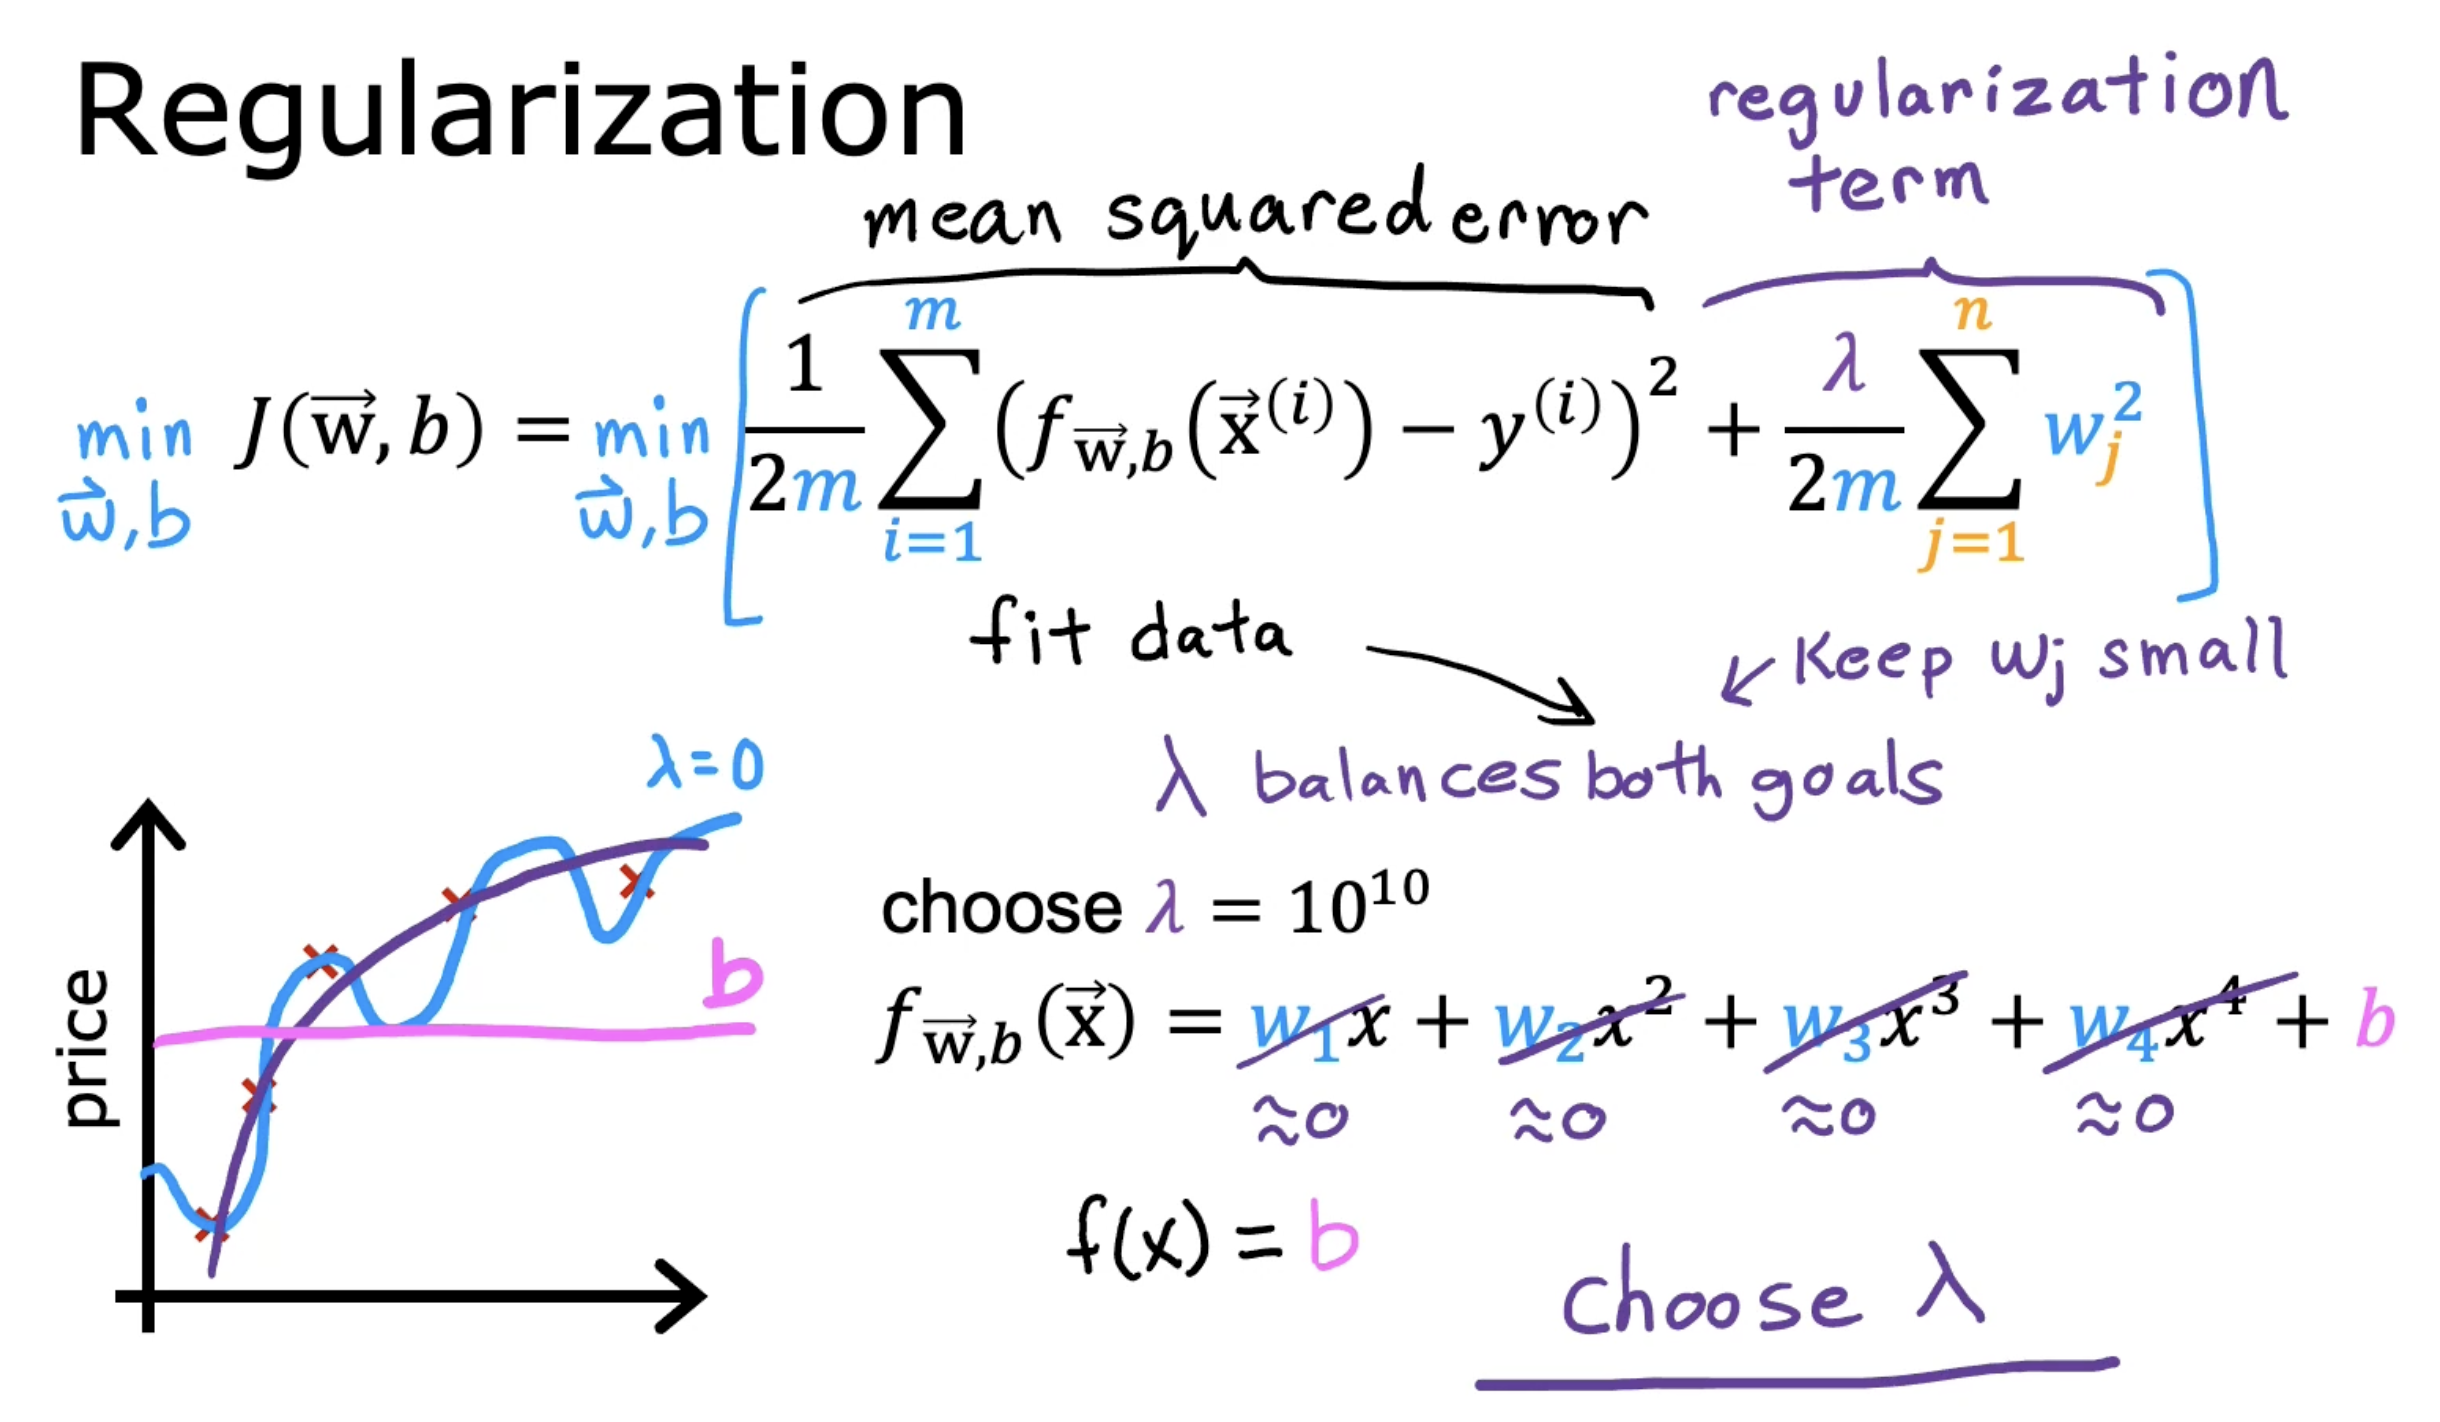

### Regularized linear regression

Expanding the partial derivative for gradient descent **with regularization:**

$$
% Partial derivatives
\frac{\partial}{\partial w_j} J(\vec{w}, b)
= \frac{1}{m} \sum_{i=1}^{m} \left( f_{\vec{w},b}\!\left(\vec{x}^{(i)}\right) - y^{(i)} \right) x_j^{(i)} + \frac{\lambda}{m} w_j \\

\frac{\partial}{\partial b} J(\vec{w}, b)
= \frac{1}{m} \sum_{i=1}^{m} \left( f_{\vec{w},b}\!\left(\vec{x}^{(i)}\right) - y^{(i)} \right) \\
$$

Note: We do not regularize $b$.

The **simultaneous update** we carry out until convergence is then

$$
% Full expanded updates
\begin{align*}
w_j &= w_j - \alpha \left[ \frac{1}{m} \sum_{i=1}^{m} \left( f_{\vec{w},b}\!\left(\vec{x}^{(i)}\right) - y^{(i)} \right) x_j^{(i)} + \frac{\lambda}{m} w_j \right] \\
b &= b - \alpha \, \frac{1}{m} \sum_{i=1}^{m} \left( f_{\vec{w},b}\!\left(\vec{x}^{(i)}\right) - y^{(i)} \right)
\end{align*}
$$


### Regularized logistic regression

The formulas for regularized logistic regression is **exactly the same** as the ones from linear regression. 

Except $f_{\vec{w},b}\!\left(\vec{x}^{(i)}\right) = \frac{1}{1+e^{-(\vec{w} \cdot \vec{x} + b)}}$ the **logistic function.**